### Работа с Jupyter и pandas, результат ipynb-файл со скриптом:

1. Считать данные из "test_dataset.csv"
2. Вывести основные статистические метрики по каждому числовому столбцу:
    - кол-во записей,
    - min, max, среднее,
    - стандартное отклонение
3. Вывести типы данных каждого столбца

In [11]:
import pandas as pd
from preprocess import preprocess_test_df
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [22]:
project_dir = Path().parent.resolve().parent
test_path = project_dir / 'data' / 'test_dataset.csv'
test_df = pd.read_csv(test_path, delimiter='|')

Для начала требуется привести к формату типов данных:
- "lat", "lon" - привести к float
- object_id - привести к int 
- load_date - привести к datetime 
- остальные колонки к str 

In [23]:
test_df.info()
test_df.head(2)

<class 'pandas.DataFrame'>
RangeIndex: 513083 entries, 0 to 513082
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   uuid            513083 non-null  str    
 1   object_id       512956 non-null  float64
 2   complex_name    512955 non-null  str    
 3   developer_name  509648 non-null  str    
 4   price           513083 non-null  float64
 5   square          513083 non-null  float64
 6   lat             512956 non-null  str    
 7   lon             512956 non-null  str    
 8   wall_type       499140 non-null  str    
 9   load_date       513083 non-null  str    
 10  city            513083 non-null  str    
 11  data_source     513083 non-null  str    
dtypes: float64(3), str(9)
memory usage: 47.0 MB


,uuid,object_id,complex_name,developer_name,price,square,lat,lon,wall_type,load_date,city,data_source
0,fb1f29ac-580d-477f-aadc-e99a8c059302,2.064599e+09,ЖК ПАРК У ДОМА,ГК ВКБ-НОВОСТРОЙКИ,7374439.0,42.79,"45,05212","39,03559",кирпично-монолитный,2025-07-08 07:10:35,krasnodar_kray,Домклик
1,a0863fab-e269-432a-aadc-f25238baedda,3.048656e+08,Городские сады,Союз застройщиков,9285642.0,64.98,"51,7281372395077","39,1954375184916",panel,2025-04-04 14:12:05,voronezh,ЦИАН


In [25]:
test_df = preprocess_test_df(test_df)
test_df.to_csv(project_dir / 'data' / 'preprocess' / 'preprocessed.csv', sep='|', index=False)

#### Получение описательной статистики

без поля дата, так как там не число, а datetime

In [26]:
number_columns = ["object_id", "price", "square", "lat", "lon"]
test_df[number_columns].describe().round(2)

,object_id,price,square,lat,lon
count,512956.0,513083.0,513083.0,512956.0,512956.0
mean,908536448.75,9507278.84,50.74,53.0,48.46
std,904635185.47,7599129.75,19.8,5.11,11.33
min,477764.0,315000.0,3.5,43.43,33.53
25%,294565491.25,6091575.0,36.9,45.14,38.92
50%,314357817.5,8132160.0,46.45,55.74,39.9
75%,2061635101.25,10686240.0,62.29,56.84,60.61
max,2068287976.0,1212988500.0,701.29,66.14,113.38


### Выведем информацию о типах данных с каждого столбца после приведения к типам данных

In [27]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 513083 entries, 0 to 513082
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   uuid            513083 non-null  str           
 1   object_id       512956 non-null  Int64         
 2   complex_name    512955 non-null  str           
 3   developer_name  509648 non-null  str           
 4   price           513083 non-null  Float64       
 5   square          513083 non-null  Float64       
 6   lat             512956 non-null  Float64       
 7   lon             512956 non-null  Float64       
 8   wall_type       499140 non-null  str           
 9   load_date       513083 non-null  datetime64[us]
 10  city            513083 non-null  str           
 11  data_source     513083 non-null  str           
dtypes: Float64(4), Int64(1), datetime64[us](1), str(6)
memory usage: 49.4 MB


### В Данных имеются пропуски
Пропуски могут свидетельствовать о том, что некоторые данные в рамках бизнес-процессов могут отсутствовать или часть данных могли не подтянутся. Требуется посмотреть что пропущено

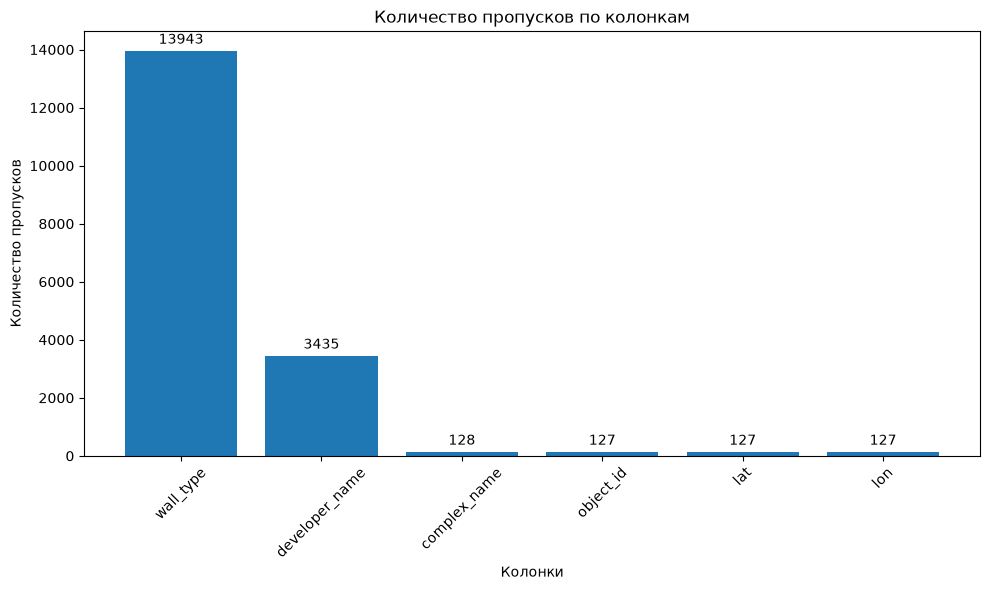

In [28]:
def plot_miss_values():
    """Строит столбчатую гистограмму столбцов, где есть пропуски и в каком количестве"""
    missing_values = (
        test_df.isna()
        .sum()
        .loc[lambda x: x > 0]
        .sort_values(ascending=False)
    )
    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.bar(missing_values.index, missing_values.values)
    ax.bar_label(bars, fmt="%.0f", padding=3)
    ax.set_title("Количество пропусков по колонкам")
    ax.set_xlabel("Колонки")
    ax.set_ylabel("Количество пропусков")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()
plot_miss_values()

Рассмотрим как количество пропусков зависят от источников и городов.

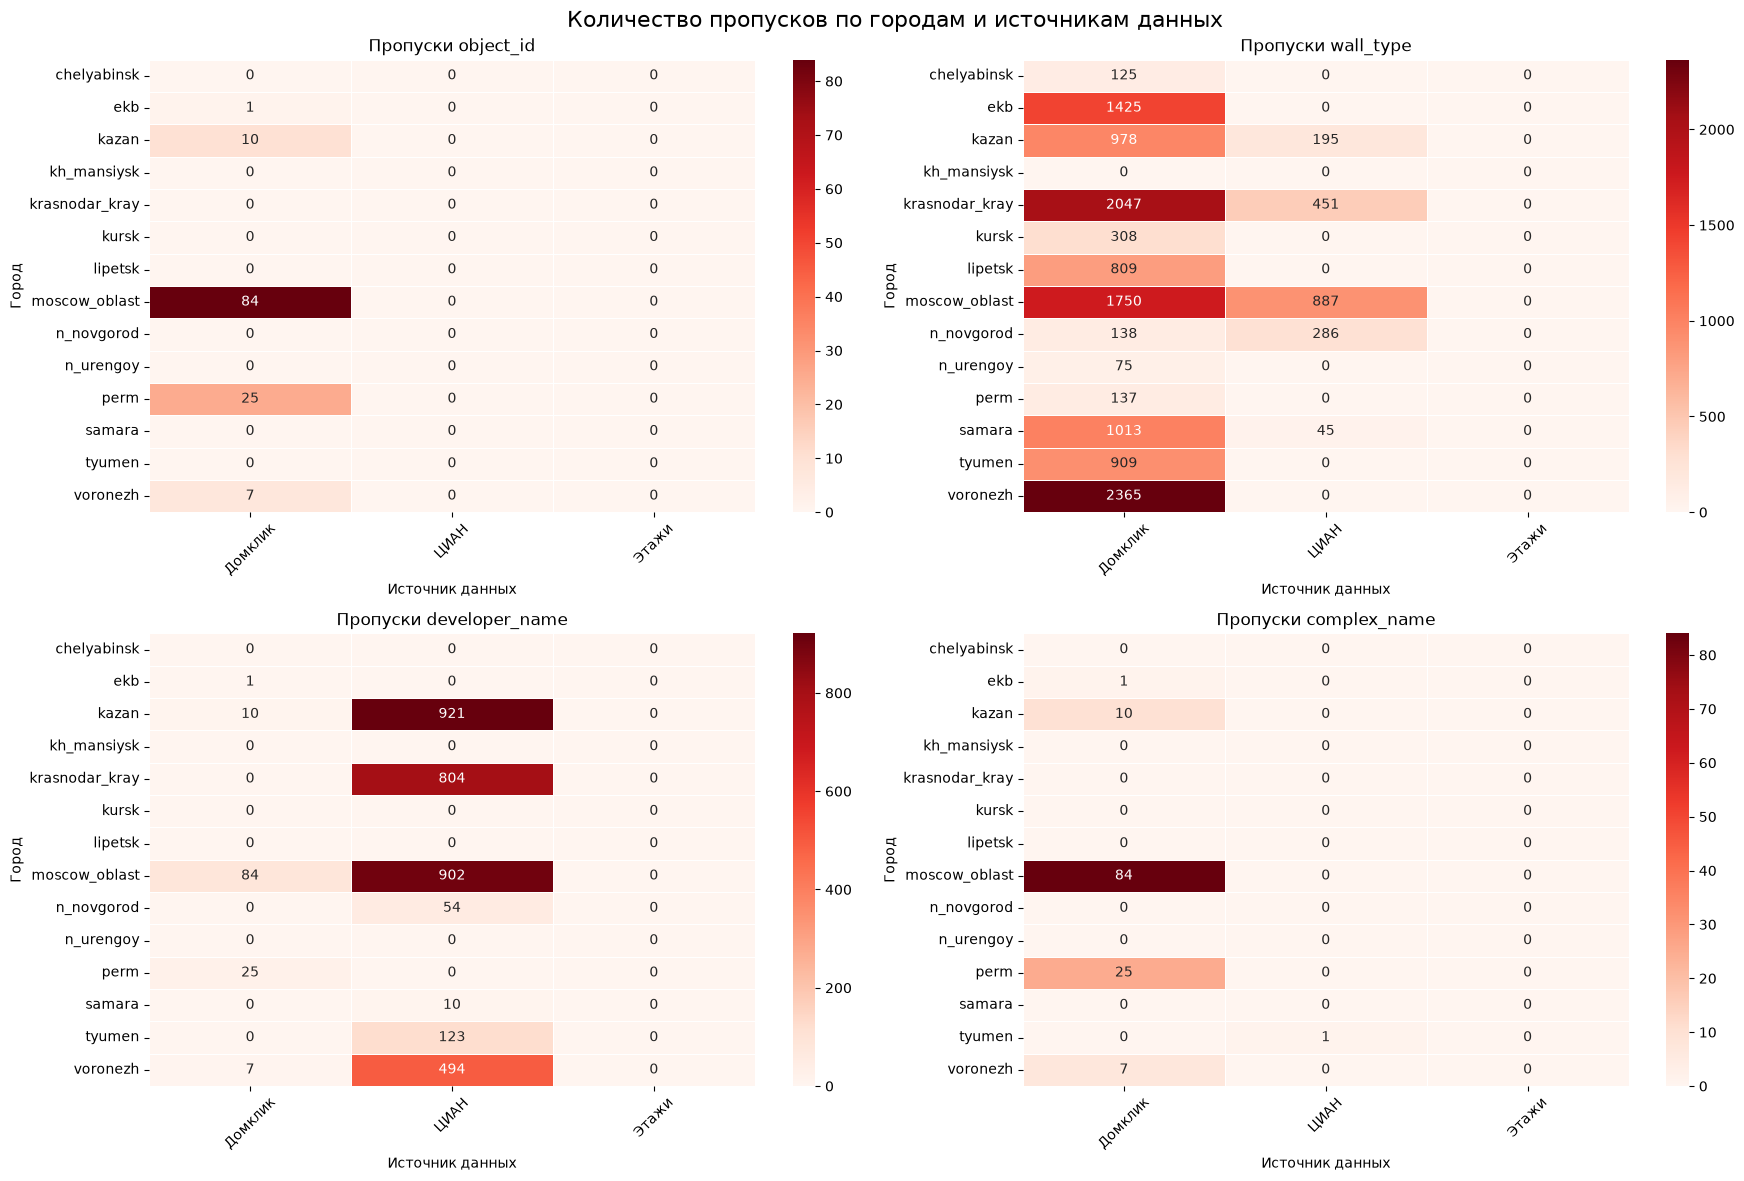

In [ ]:
def plot_heatmap_missing_by_source():
    """Визуализация heatmap по столбцам с пропусками"""
    columns = [
        ("object_id", "Пропуски object_id"),
        ("wall_type", "Пропуски wall_type"),
        ("developer_name", "Пропуски developer_name"),
        ("complex_name", "Пропуски complex_name"),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(18, 12))

    for ax, (col, title) in zip(axes.flat, columns):
        missing_pivot = (
            test_df.assign(missing=test_df[col].isna().astype(int))
            .pivot_table(
                index="city",
                columns="data_source",
                values="missing",
                aggfunc="sum",
                fill_value=0
            )
        )

        sns.heatmap(
            missing_pivot,
            annot=True,
            fmt=".0f",
            cmap="Reds",
            linewidths=0.5,
            ax=ax
        )

        ax.set_title(title)
        ax.set_xlabel("Источник данных")
        ax.set_ylabel("Город")
        ax.tick_params(axis="x", rotation=45)
        ax.tick_params(axis="y", rotation=0)

    fig.suptitle(
        "Количество пропусков по городам и источникам данных",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()
plot_heatmap_missing_by_source()

Вывод по графикам:
- Идентификаторы объекта не отображаются для перми и моск. области из <b>Домклика</b>
- Тип стен объекта не отображаются для перми и моск. области из <b>Домклика</b> и <b>Циан</b>
- Наименование девелопера не отображается для <b>Циан и Домклик</b>
- object_name предположительно связан с complex_name исходия из наименования столбцов и количества пропусков.